# Rossmann Store Sales – Sales on Promotion Days

**Question:** How much higher are daily sales on promotion days, after controlling for
day of week, season, day of month, holidays and differences between stores?

In [1]:
try:
    import linearmodels
except ImportError:
    !pip install linearmodels -q

# Works both in Google Colab and locally (after git clone)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/rossmann-sales-analysis/'
except ImportError:
    BASE_DIR = '../'

DATA_DIR = BASE_DIR + 'data/'
FIG_DIR = BASE_DIR + 'figures/'

import numpy as np
import pandas as pd
from linearmodels.panel import PanelOLS

df = pd.read_parquet(DATA_DIR + 'train_clean.parquet')

Mounted at /content/drive


In [2]:
# Exclude Sundays: only 33 special stores are open, and promotions never run on Sundays
df = df[df['DayOfWeek'] != 7].copy()

df['log_sales'] = np.log(df['Sales'])
df['Month'] = df['Date'].dt.month
df['Year'] = df['Date'].dt.year
df['Day'] = df['Date'].dt.day

# Cluster identifiers: store and calendar week (week starts on Monday)
week_start = df['Date'] - pd.to_timedelta(df['Date'].dt.dayofweek, unit='D')
df['WeekId'] = pd.factorize(week_start)[0]
df['StoreId'] = df['Store']

In [9]:
# Promo is set chain-wide: same value for all stores on each date
print('Dates where stores differ in Promo:', (df.groupby('Date')['Promo'].nunique() > 1).sum())

# ... and constant within each week (Mon–Fri)
wk = df[df['DayOfWeek'] <= 5].groupby('WeekId')['Promo'].agg(['nunique', 'max'])
print('Weeks:', len(wk), '| weeks with mixed promo status:', (wk['nunique'] > 1).sum(),
      '| promo weeks:', int(wk['max'].sum()))

# Promotions are not evenly spread over the month
days_only = df[df['DayOfWeek'] <= 5].drop_duplicates('Date')
print('\nShare of promo days by day of month:')
print(days_only.groupby(pd.cut(days_only['Day'], [0, 5, 10, 15, 20, 25, 31]),
                        observed=True)['Promo'].mean().round(2))

# How often does a non-promo week directly follow a promo week?
p = wk['max'].sort_index(ascending=False).values   # oldest week first
print('\nNon-promo weeks directly after a promo week:',
      ((p[1:] == 0) & (p[:-1] == 1)).sum(), 'of', (p == 0).sum())

Dates where stores differ in Promo: 0
Weeks: 135 | weeks with mixed promo status: 0 | promo weeks: 72

Share of promo days by day of month:
Day
(0, 5]      0.77
(5, 10]     0.54
(10, 15]    0.33
(15, 20]    0.72
(20, 25]    0.40
(25, 31]    0.45
Name: Promo, dtype: float64

Non-promo weeks directly after a promo week: 60 of 63


In [4]:
panel = df.set_index(['Store', 'Date'])
clusters = panel[['StoreId', 'WeekId']]

def fit(formula):
    """Panel OLS with standard errors clustered by store and week."""
    return PanelOLS.from_formula(formula, data=panel).fit(cov_type='clustered', clusters=clusters)

pct = lambda x: 100 * (np.exp(x) - 1)

def promo_effect(res, name):
    b = res.params['Promo']
    lo, hi = res.conf_int().loc['Promo']
    print(f'{name}: {pct(b):+.1f}%  (95% CI: {pct(lo):+.1f}% to {pct(hi):+.1f}%)')

In [5]:
controls = 'C(DayOfWeek) + C(Month) + C(Year) + C(StateHoliday) + SchoolHoliday'

res1 = fit('log_sales ~ 1 + Promo')
res2 = fit(f'log_sales ~ 1 + Promo + {controls}')
res3 = fit(f'log_sales ~ 1 + Promo + {controls} + EntityEffects')
res4 = fit(f'log_sales ~ 1 + Promo + {controls} + C(Day) + EntityEffects')

promo_effect(res1, 'Model 1 (no controls)     ')
promo_effect(res2, 'Model 2 (+ time controls) ')
promo_effect(res3, 'Model 3 (+ store FE)      ')
promo_effect(res4, 'Model 4 (+ day of month)  ')

Model 1 (no controls)     : +41.5%  (95% CI: +38.1% to +45.0%)
Model 2 (+ time controls) : +39.3%  (95% CI: +36.6% to +42.2%)
Model 3 (+ store FE)      : +39.3%  (95% CI: +36.5% to +42.2%)
Model 4 (+ day of month)  : +37.3%  (95% CI: +34.6% to +40.0%)


In [6]:
days = {1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri'}
for d, name in days.items():
    panel[f'Promo_{name}'] = ((panel['Promo'] == 1) & (panel['DayOfWeek'] == d)).astype(int)

promo_terms = ' + '.join(f'Promo_{n}' for n in days.values())
res5 = fit(f'log_sales ~ 1 + {promo_terms} + {controls} + C(Day) + EntityEffects')

ci = res5.conf_int()
for n in days.values():
    v = f'Promo_{n}'
    print(f'{n}: {pct(res5.params[v]):+.1f}%  '
          f'(95% CI: {pct(ci.loc[v, "lower"]):+.1f}% to {pct(ci.loc[v, "upper"]):+.1f}%)')

Mon: +57.7%  (95% CI: +52.1% to +63.4%)
Tue: +43.8%  (95% CI: +38.9% to +49.0%)
Wed: +35.3%  (95% CI: +31.1% to +39.7%)
Thu: +30.0%  (95% CI: +26.6% to +33.4%)
Fri: +22.2%  (95% CI: +19.3% to +25.2%)


In [7]:
for a, b in [('Mon', 'Fri'), ('Wed', 'Thu')]:
    t = res5.wald_test(formula=f'Promo_{a} = Promo_{b}')
    print(f'{a} vs {b}: chi2 = {t.stat:.1f}, p = {t.pval:.4f}')

Mon vs Fri: chi2 = 147.3, p = 0.0000
Wed vs Thu: chi2 = 6.6, p = 0.0100


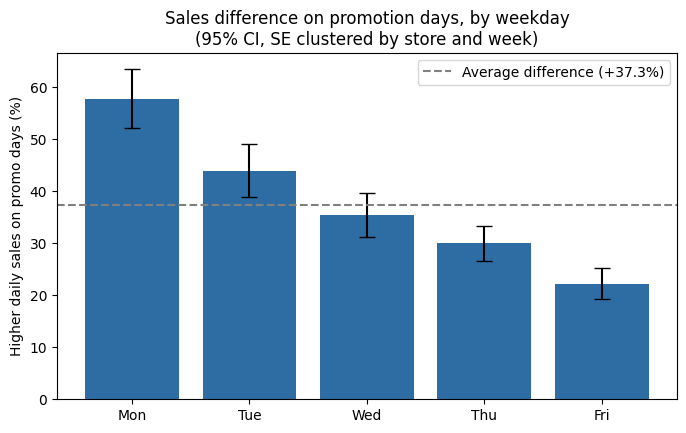

In [8]:
import matplotlib.pyplot as plt

names = list(days.values())
effect = [pct(res5.params[f'Promo_{n}']) for n in names]
lower = [pct(ci.loc[f'Promo_{n}', 'lower']) for n in names]
upper = [pct(ci.loc[f'Promo_{n}', 'upper']) for n in names]
err = [[e - l for e, l in zip(effect, lower)],
       [u - e for e, u in zip(effect, upper)]]
avg = pct(res4.params['Promo'])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(names, effect, yerr=err, capsize=6, color='#2E6DA4')
ax.axhline(avg, linestyle='--', color='grey', label=f'Average difference (+{avg:.1f}%)')
ax.set_ylabel('Higher daily sales on promo days (%)')
ax.set_title('Sales difference on promotion days, by weekday\n(95% CI, SE clustered by store and week)')
ax.legend()
plt.savefig(FIG_DIR + 'promo_effect_by_weekday.png', dpi=150, bbox_inches='tight')
plt.show()

## Results: sales difference on promotion days

| Model | Controls | Difference | 95% CI |
|---|---|---|---|
| 1 | none | +41.5% | +38.1% to +45.0% |
| 2 | day of week, month, year, holidays | +39.3% | +36.6% to +42.2% |
| 3 | + store fixed effects | +39.3% | +36.5% to +42.2% |
| 4 | + day of month | **+37.3%** | +34.6% to +40.0% |

- Time controls reduce the estimate, because promotions never run on Saturdays, which
  have slightly lower sales.
- Store fixed effects do not change it: promotions are scheduled chain-wide, so all stores
  have the same promo status on every date.
- Day of month matters: 77% of weekdays on days 1–5 of a month are promo days, but only 33%
  on days 11–15. Without this control, start-of-month effects (e.g. pay day) are partly
  attributed to promotions.
- Promo status is constant within each week (135 weeks, 72 of them promo weeks). Standard
  errors are therefore clustered by store and week.

## Results: difference by weekday (Model 5)

| Day | Difference | 95% CI |
|---|---|---|
| Mon | +57.7% | +52.1% to +63.4% |
| Tue | +43.8% | +38.9% to +49.0% |
| Wed | +35.3% | +31.1% to +39.7% |
| Thu | +30.0% | +26.6% to +33.4% |
| Fri | +22.2% | +19.3% to +25.2% |

The difference decreases steadily during the week. Wald tests confirm that Monday differs
from Friday (χ² = 147.3, p < 0.001) and Wednesday from Thursday (χ² = 6.6, p = 0.010).
Possible explanation (hypothesis): promotions start on Mondays and customers react early
in the promo week.

## Limitations

- This is an observational comparison, not a causal effect. Promotions were not randomly
  assigned, and anything else happening chain-wide in promo weeks (e.g. advertising) is
  included in the estimate.
- Promo and non-promo weeks alternate: 60 of the 63 non-promo weeks directly follow a promo
  week. If customers move purchases into promo weeks (pull-forward), sales in the comparison
  weeks are lower than normal, and the difference overstates the additional sales created
  by promotions. The data cannot separate these two effects.
- Sundays were excluded (only 33 special stores open, no promotions on Sundays).